# Features Engineering
Phần này sẽ giải quyết việc chọn các feature như thế nào cho phù hợp và tối ưu để huấn luyện model.

Các chiến thuật Tạo mới đặc trưng mới, biến đổi đặc trưng

Chọn lựa đặc trưng: 

   - Dùng các mô hình máy học LASSO, Ridge, ElasticNet, Decision Tree, Random Forest để tìm các đặc trưng quan trọng

   - Dựa trên phân tích thống kê ở bước EDA

   - Chiến thuật để bỏ đặc trưng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
from lightgbm import early_stopping, log_evaluation
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
import seaborn as sns
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Tìm kiếm thêm đặc trưng mới
Nhận thấy việc bán lẻ, các cửa hàng sẽ có xu hướng bị ảnh hưởng bởi các đặc trưng như giá vàng, sự kiến MMA, thiên tai

## 🟡 1. Giá vàng
### Giả định ảnh hưởng:

- Giá vàng thường được xem như một chỉ báo kinh tế. Khi giá vàng tăng mạnh, nó thường phản ánh tâm lý bất ổn kinh tế, khiến người dân tiết kiệm hơn —> giảm chi tiêu ở siêu thị.

- Ngược lại, giá vàng giảm có thể khiến người dân thấy kinh tế ổn định hơn —> tăng chi tiêu.

### Cách kiểm chứng dữ liệu:

- Lấy dữ liệu giá vàng hàng ngày hoặc hàng tuần.

- Kết hợp với dữ liệu bán hàng theo thời gian.

- Sử dụng hệ số tương quan (correlation) hoặc mô hình hồi quy tuyến tính để xem mối liên hệ giữa giá vàng và doanh số bán.

### Lưu ý theo bang:

- California có dân số đông, dễ chịu ảnh hưởng bởi tâm lý kinh tế vĩ mô.

- Texas có nhiều người đầu tư vào vàng, có thể nhạy cảm hơn.

- Wisconsin có thể ít bị ảnh hưởng hơn nếu tiêu dùng thiên về thiết yếu.

In [8]:
df = pd.read_parquet('../data/train_val.parquet').head(100000)
print(df.columns)
print(df['date'].unique())

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc', 'humidity', 'gold_price'],
      dtype='object')
['2013-11-22T00:00:00.000000000' '2013-11-23T00:00:00.000000000'
 '2013-11-24T00:00:00.000000000' '2013-11-25T00:00:00.000000000']


In [9]:
print(df['state_id'].unique())

[1 2 3]


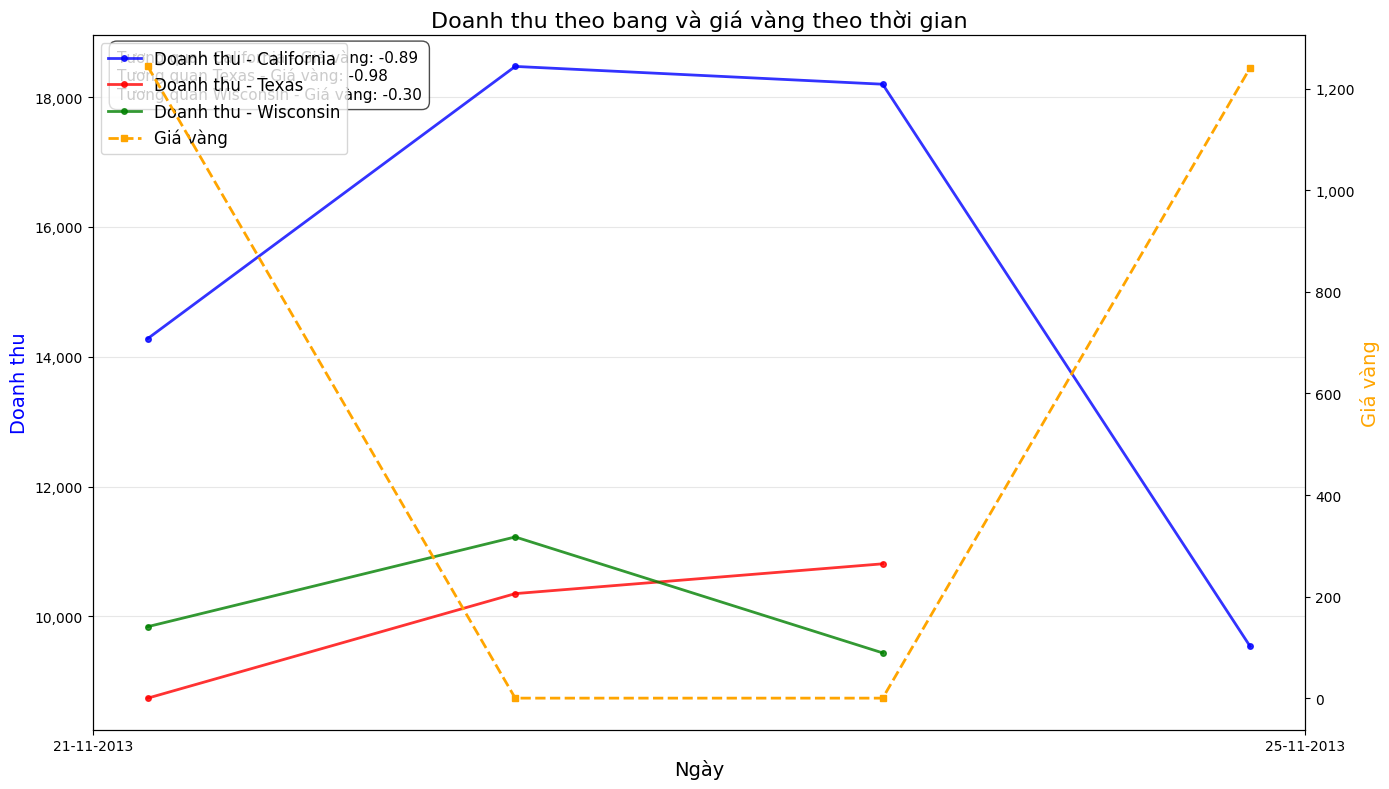

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Giả sử df là DataFrame của bạn đã có sẵn
# Nếu cần, hãy thay thế phần này bằng code để đọc dữ liệu của bạn
# df = pd.read_csv('đường_dẫn_đến_file.csv')

# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Lấy giá vàng cho mỗi ngày (giả sử giá vàng giống nhau trong một ngày)
gold_prices = df.groupby('date')['gold_price'].first()

# Tạo một figure với 2 trục y
fig, ax1 = plt.subplots(figsize=(14, 8))

# Đặt trục y thứ hai cho giá vàng
ax2 = ax1.twinx()

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang trên trục y thứ nhất
for i, state in enumerate(daily_revenue_by_state.columns):
    ax1.plot(
        daily_revenue_by_state.index, 
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Vẽ đường giá vàng trên trục y thứ hai
ax2.plot(
    gold_prices.index,
    gold_prices.values,
    color='orange',
    marker='s',
    markersize=4,
    linewidth=2,
    linestyle='--',
    label='Giá vàng'
)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
# Xác định ngày đầu tiên và cuối cùng trong dữ liệu
first_date = min(daily_revenue_by_state.index.min(), gold_prices.index.min())
last_date = max(daily_revenue_by_state.index.max(), gold_prices.index.max())

# Tạo một mảng các ngày với khoảng cách 50 ngày
date_range = pd.date_range(start=first_date, end=last_date, freq='50D')

# Thiết lập các vị trí và nhãn cho trục x
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))

# Đặt tiêu đề và nhãn
ax1.set_title('Doanh thu theo bang và giá vàng theo thời gian', fontsize=16)
ax1.set_xlabel('Ngày', fontsize=14)
ax1.set_ylabel('Doanh thu', fontsize=14, color='blue')
ax2.set_ylabel('Giá vàng', fontsize=14, color='orange')

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax2.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Kết hợp legends từ cả hai trục
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, fontsize=12)

# Thêm lưới để dễ đọc
ax1.grid(True, alpha=0.3)

# Tính tương quan giữa giá vàng và doanh thu cho mỗi bang và hiển thị
corr_text = []
for state in daily_revenue_by_state.columns:
    # Kết hợp dữ liệu để tính toán tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'gold_price': gold_prices
    }).dropna()
    
    corr = state_data['revenue'].corr(state_data['gold_price'])
    corr_text.append(f'Tương quan {state} - Giá vàng: {corr:.2f}')

# Hiển thị thông tin tương quan ở góc trái trên
ax1.annotate(
    '\n'.join(corr_text),
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

## 🥋 2. Sự kiện MMA
### Giả định ảnh hưởng:

- Các sự kiện thể thao lớn (đặc biệt là UFC, WWE...) thường dẫn tới mua sắm trước sự kiện như đồ ăn nhanh, bia, snack, v.v.

- Doanh số ở các siêu thị thường tăng nhẹ vào 1–2 ngày trước và ngày diễn ra sự kiện.

### Cách kiểm chứng:

- Thu thập lịch sự kiện MMA/UFC (ví dụ từ UFC hoặc Tapology).

- Xác định ngày diễn ra và khu vực tổ chức (ví dụ nếu sự kiện ở Texas thì sức ảnh hưởng cục bộ có thể cao hơn).

- So sánh doanh số siêu thị trong khoảng 3 ngày xung quanh sự kiện vs các ngày bình thường bằng t-test hoặc boxplot.

### Lưu ý theo bang:

- Texas và California thường tổ chức sự kiện lớn hơn, nên khả năng ảnh hưởng sẽ cao hơn.

- Wisconsin có thể bị ảnh hưởng gián tiếp qua truyền hình.

## 🌪 3. Ngày diễn ra thiên tai
### Giả định ảnh hưởng:

- Trước thiên tai (như bão, lốc xoáy, cháy rừng), người dân thường tăng mua hàng thiết yếu: nước, đồ hộp, nến, pin, thuốc.

- Sau thiên tai, có thể doanh số giảm tạm thời nếu giao thông, điện bị gián đoạn.

### Cách kiểm chứng:

- Lấy dữ liệu thời tiết và thiên tai lịch sử theo từng bang (NOAA, weather.gov).

- Đánh dấu thời điểm và vị trí thiên tai.

- So sánh doanh số siêu thị 1–2 ngày trước thiên tai và ngày sau thiên tai.

### Lưu ý theo bang:

- California: cháy rừng, động đất.

- Texas: bão, lũ.

- Wisconsin: bão tuyết, lốc xoáy.